<a href="https://colab.research.google.com/github/vijayalakshmips2530/aryan-student-developer/blob/main/01_karnataka_schools_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 01: Schools in Karnataka, district by district (2019-20)
**Training module: Data Analysis with Python (pandas)** · Author: Vijaya Lakshmi P S

**Data:** District-wise number of schools in Karnataka, 2019-20 (Karnataka Open Data portal, karnataka.data.gov.in).

**What you will learn**
1. Read a messy government CSV (multi-row header, subtotal rows, codes inside names).
2. Clean it step by step with pandas and check the result against the official totals.
3. Answer five real questions with tables and three charts.
4. Explain your findings in plain words.

> *Reference version: read every step, change it, and rewrite the findings in your own words before you publish it.*

## Step 1. Load the file
The file has **3 header rows**, so we skip them and name the columns ourselves.

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

PATH = "data/DistrictWiseSchools2019_20.csv"
if not os.path.exists(PATH):                  # in Colab: upload the CSV when asked
    from google.colab import files
    PATH = list(files.upload().keys())[0]

raw = pd.read_csv(PATH, header=None, skiprows=3, encoding="utf-8-sig")
print(raw.shape)
raw.head()

Saving DistrictWiseSchools2019_20.csv to DistrictWiseSchools2019_20.csv
(312, 18)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,1,01-All Management,BAGALKOT-2902,522,153,675,891,376,1267,1413,529,1942,313,189,502,63,85,148
1,2,01-All Management,BALLARI-2912,684,190,874,1048,579,1627,1732,769,2501,370,300,670,79,112,191
2,3,01-All Management,BELAGAVI CHIKKODI-2930,760,144,904,1279,369,1648,2039,513,2552,425,177,602,130,65,195
3,4,01-All Management,BELAGAVI-2901,576,102,678,878,318,1196,1454,420,1874,323,184,507,87,81,168
4,5,01-All Management,BENGALURU RURAL-2921,621,30,651,583,111,694,1204,141,1345,217,72,289,42,41,83


In [ ]:
pd.set_option("display.max_rows", None)
raw


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,1,01-All Management,BAGALKOT-2902,522,153,675,891,376,1267,1413,529,1942,313,189,502,63,85,148
1,2,01-All Management,BALLARI-2912,684,190,874,1048,579,1627,1732,769,2501,370,300,670,79,112,191
2,3,01-All Management,BELAGAVI CHIKKODI-2930,760,144,904,1279,369,1648,2039,513,2552,425,177,602,130,65,195
3,4,01-All Management,BELAGAVI-2901,576,102,678,878,318,1196,1454,420,1874,323,184,507,87,81,168
4,5,01-All Management,BENGALURU RURAL-2921,621,30,651,583,111,694,1204,141,1345,217,72,289,42,41,83
5,6,01-All Management,BENGALURU U NORTH-2928,103,197,300,169,1527,1696,272,1724,1996,107,1078,1185,27,383,410
6,7,01-All Management,BENGALURU U SOUTH-2920,230,270,500,412,2067,2479,642,2337,2979,222,1394,1616,75,763,838
7,8,01-All Management,BIDAR-2905,605,127,732,990,438,1428,1595,565,2160,341,246,587,58,141,199
8,9,01-All Management,CHAMARAJANAGARA-2927,361,36,397,475,100,575,836,136,972,160,69,229,35,48,83
9,10,01-All Management,CHIKKABALLAPURA-2929,900,45,945,661,169,830,1561,214,1775,232,91,323,52,69,121


## Step 2. Give the columns proper names
School levels: lower primary, upper primary, elementary (= lower + upper primary), secondary, higher secondary (PU sections). Each is split into rural, urban and total.

In [ ]:
levels = ["lower_primary", "upper_primary", "elementary", "secondary", "higher_secondary"]
num_cols = [f"{lv}_{area}" for lv in levels for area in ["rural", "urban", "total"]]
raw.columns = ["sl_no", "management", "district"] + num_cols
raw.head(3)

,sl_no,management,district,lower_primary_rural,lower_primary_urban,lower_primary_total,upper_primary_rural,upper_primary_urban,upper_primary_total,elementary_rural,elementary_urban,elementary_total,secondary_rural,secondary_urban,secondary_total,higher_secondary_rural,higher_secondary_urban,higher_secondary_total
0,1,01-All Management,BAGALKOT-2902,522,153,675,891,376,1267,1413,529,1942,313,189,502,63,85,148
1,2,01-All Management,BALLARI-2912,684,190,874,1048,579,1627,1732,769,2501,370,300,670,79,112,191
2,3,01-All Management,BELAGAVI CHIKKODI-2930,760,144,904,1279,369,1648,2039,513,2552,425,177,602,130,65,195


In [ ]:
print(raw.shape)

(312, 18)


## Step 3. Separate the rows we want from the rows we do not
- The last row is a **grand total** (management is empty).
- After every management group there is a **subtotal** row (district is empty).
We keep the subtotals for checking, and drop the grand total.

In [ ]:
raw = raw.dropna(subset=["management"])                 # drop the grand total row
state_totals = raw[raw["district"].isna()].copy()       # subtotal rows
schools = raw[raw["district"].notna()].copy()           # district rows
print("district rows:", len(schools), "| subtotal rows:", len(state_totals))

district rows: 296 | subtotal rows: 15


## Step 4. Clean the text
District names carry a code (`BAGALKOT-2902`) and management names start with a number (`01-All Management`).

In [ ]:
schools["district"] = (schools["district"].str.replace(r"-\d+$", "", regex=True).str.strip().str.title())
for df in (schools, state_totals):
    df["management"] = df["management"].str.replace(r"^\d+-", "", regex=True).str.strip()

schools[num_cols] = schools[num_cols].apply(pd.to_numeric)
state_totals[num_cols] = state_totals[num_cols].apply(pd.to_numeric)
print(schools["management"].unique())
print(sorted(schools["district"].unique())[:8], "...")

['All Management' 'Department of Education'
 'Tribal Welfare Department Schools' 'Local body' 'Pvt. Aided'
 'Pvt. Unaided' 'Others State Govt. Managed Schools' 'Un-Recognised'
 'Social Welfare Department Schools' 'Ministry of Labor'
 'Kendriya Vidyalay / Central Schools' 'Javahar Navodaya Vidyalaya'
 'Sainik Schools' 'Railway Schools' 'Central Tibatin Schools']
['Bagalkot', 'Ballari', 'Belagavi', 'Belagavi Chikkodi', 'Bengaluru Rural', 'Bengaluru U North', 'Bengaluru U South', 'Bidar'] ...


## Step 5. Check our work
If the cleaning is right, the district rows must add up to the official subtotal of each management type.

In [ ]:
check = schools.groupby("management")[num_cols].sum()
official = state_totals.set_index("management")[num_cols].loc[check.index]
difference = (check - official).abs().sum().sum()
print("Total difference between our sums and the official totals:", difference)

Total difference between our sums and the official totals: 0


## Step 6. Question 1: Which districts have the most and the fewest elementary schools?
We use the **All Management** rows, one per district.

Most:
 district
Kalburgi             2991
Bengaluru U South    2979
Vijayapura           2881
Mysuru               2689
Hassan               2619
Name: elementary_total, dtype: int64 

Fewest:
 district
Kodagu              534
Gadag               906
Udupi               948
Chamarajanagara     972
Uttara Kannada     1066
Name: elementary_total, dtype: int64


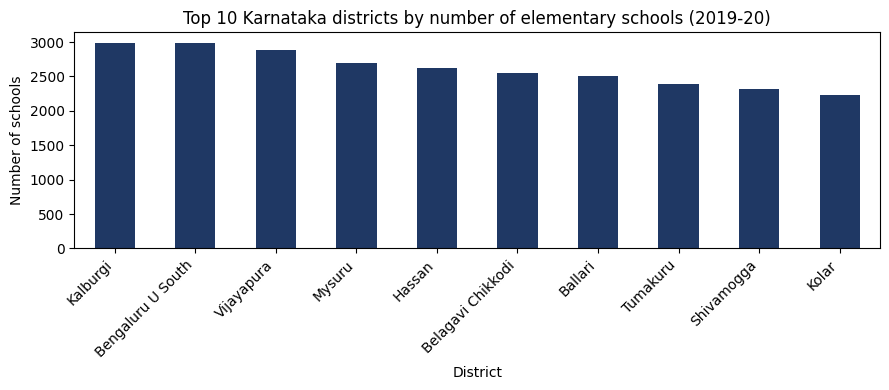

In [ ]:
allm = schools[schools["management"] == "All Management"].set_index("district")
top5 = allm["elementary_total"].nlargest(5)
bottom5 = allm["elementary_total"].nsmallest(5)
print("Most:\n", top5, "\n\nFewest:\n", bottom5)

ax = allm["elementary_total"].sort_values(ascending=False).head(10).plot(kind="bar", figsize=(9, 4), color="#1F3864")
ax.set_title("Top 10 Karnataka districts by number of elementary schools (2019-20)")
ax.set_xlabel("District"); ax.set_ylabel("Number of schools")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

**Chart 1 note:** *(write one line about what this chart shows)*

## Step 7. Question 2: Which districts are the most urban?
Share of elementary schools that are in urban areas.

district
Bengaluru U North    86.4
Bengaluru U South    78.4
Dharwad              47.0
Gadag                35.3
Ballari              30.7
Name: urban_share_%, dtype: float64


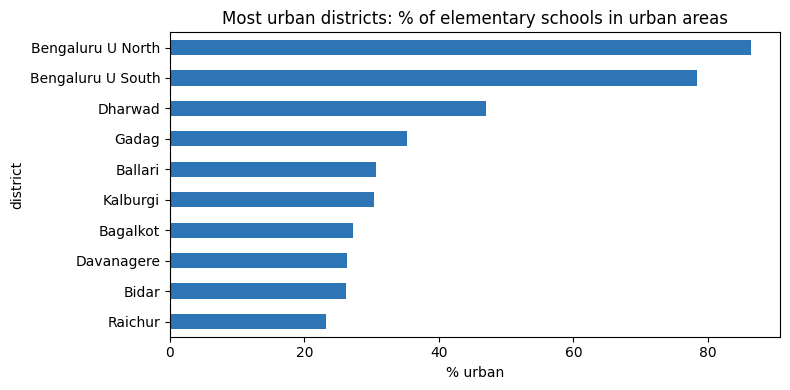

In [ ]:
allm["urban_share_%"] = (allm["elementary_urban"] / allm["elementary_total"] * 100).round(1)
urban = allm["urban_share_%"].sort_values(ascending=False)
print(urban.head(5))

ax = urban.head(10).sort_values().plot(kind="barh", figsize=(8, 4), color="#2E75B6")
ax.set_title("Most urban districts: % of elementary schools in urban areas")
ax.set_xlabel("% urban"); plt.tight_layout(); plt.show()

**Chart 2 note:** *(write one line)*

## Step 8. Question 3: Where are private unaided schools most common?

district
Bengaluru U North    67.0
Bengaluru U South    64.5
Kalburgi             30.8
Bidar                30.6
Ballari              29.5
Name: elementary_total, dtype: float64
district
Tumakuru Madhugiri      9.0
Uttara Kannada          8.4
Uttara Kannada Sirsi    4.9
Name: elementary_total, dtype: float64


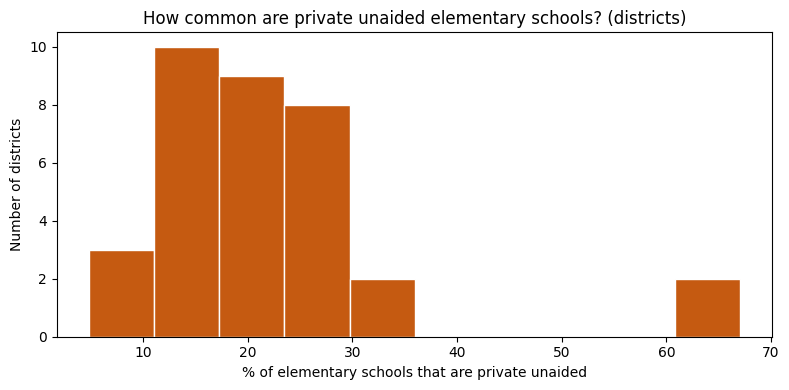

In [ ]:
pvt = schools[schools["management"] == "Pvt. Unaided"].set_index("district")["elementary_total"]
pvt_share = (pvt / allm["elementary_total"] * 100).dropna().round(1).sort_values(ascending=False)
print(pvt_share.head(5)); print(pvt_share.tail(3))

ax = pvt_share.plot(kind="hist", bins=10, figsize=(8, 4), color="#C55A11", edgecolor="white")
ax.set_title("How common are private unaided elementary schools? (districts)")
ax.set_xlabel("% of elementary schools that are private unaided"); ax.set_ylabel("Number of districts")
plt.tight_layout(); plt.show()

**Chart 3 note:** *(write one line)*

## Step 9. Question 4: Rural versus urban, level by level (whole state)

In [ ]:
state = state_totals[state_totals["management"] == "All Management"].iloc[0]
table = pd.DataFrame({
    "rural": [state[f"{lv}_rural"] for lv in levels],
    "urban": [state[f"{lv}_urban"] for lv in levels]}, index=levels)
table["urban_%"] = (table["urban"] / (table["rural"] + table["urban"]) * 100).round(1)
table

,rural,urban,urban_%
lower_primary,21199,3192,13.1
upper_primary,25744,12296,32.3
elementary,46943,15488,24.8
secondary,9428,7422,44.0
higher_secondary,2394,3564,59.8


## Step 10. Question 5: Who runs the schools? Management mix (elementary, whole state)

In [ ]:
mix = (state_totals.set_index("management")["elementary_total"]
       .drop("All Management").sort_values(ascending=False))
mix_pct = (mix / mix.sum() * 100).round(1)
pd.DataFrame({"schools": mix, "%": mix_pct}).head(6)

,schools,%
management,,
Department of Education,43282,69.3
Pvt. Unaided,14758,23.6
Pvt. Aided,2984,4.8
Tribal Welfare Department Schools,795,1.3
Social Welfare Department Schools,372,0.6
Others State Govt. Managed Schools,116,0.2


## Step 11. Findings (write these in your own words)
1.
2.
3.

## Step 12. Lab exercises for learners
1. Repeat Question 1 for **secondary** schools. Do the rankings change?
2. Which district has the biggest **gap** between rural and urban high schools?
3. Compare **Department of Education** and **Private Unaided** schools in your own district.

**Limitations to mention:** this is a count of schools, not students or teachers; data is for 2019-20 only.